# 08 — Visualizing Clearwell

Loading the synthetic benchmark city (`data/clearwell.json`) and plotting it, colored by accessibility tag, to see all four neighborhoods at a glance.

### Load the city

Plain `networkx`, not `osmnx` — Clearwell isn't a real place, so there's nothing for `osmnx` to download or plot. `nx.node_link_graph` rebuilds the exact same graph that was saved to JSON.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import networkx as nx
from src.data.synthetic_city import load_clearwell

G = load_clearwell()
print(G.number_of_nodes(), "nodes")
print(G.number_of_edges(), "edges")

95 nodes
294 edges


### Plot it, colored by accessibility tag

`pos` is a dict of `{node: (x, y)}` built from each node's own `x`/`y` attributes — `nx.draw` needs this explicitly since, unlike `osmnx.plot_graph`, plain `networkx` has no built-in idea of real-world coordinates. Edges are colored green (`wheelchair: yes/designated`), red (`wheelchair: no`), or gray (untagged) so all four neighborhoods' design patterns are visible at once.

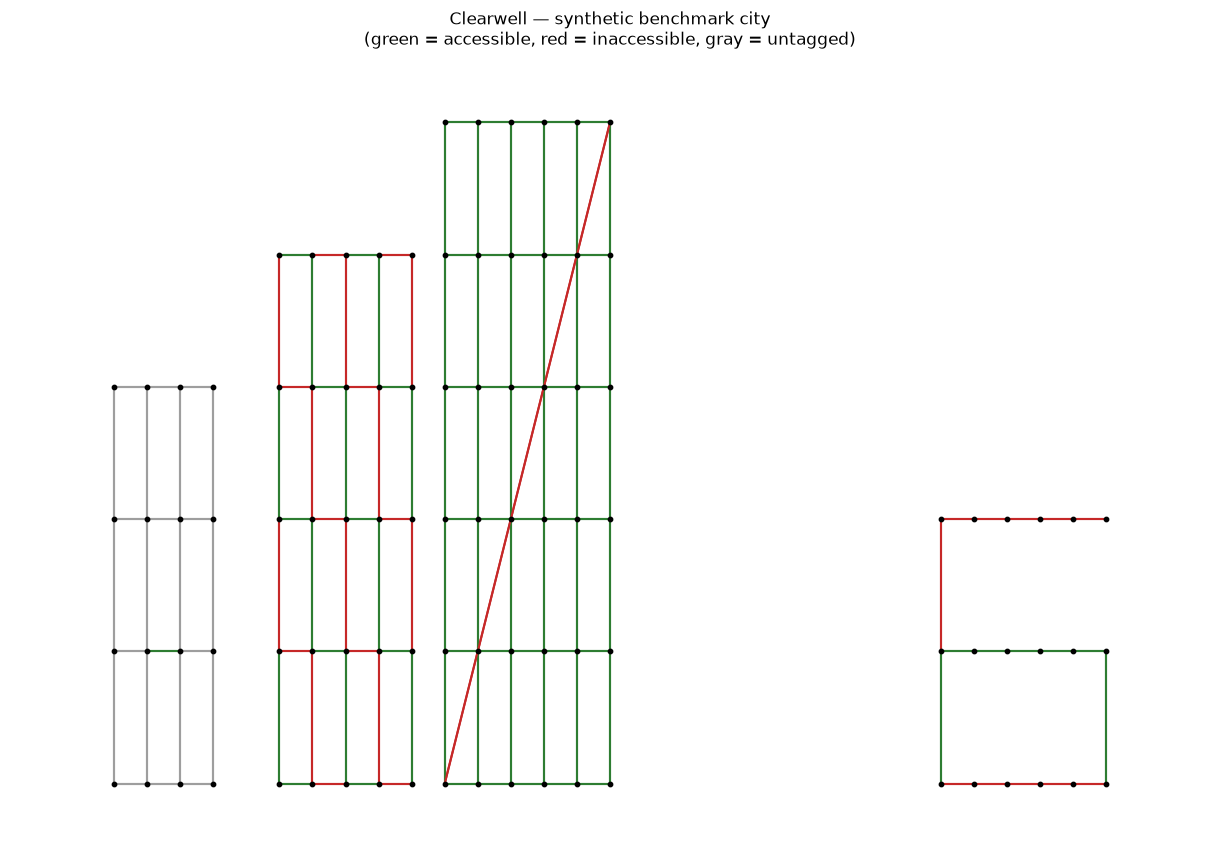

In [2]:
pos = {n: (d["x"], d["y"]) for n, d in G.nodes(data=True)}

edge_colors = []
for u, v, k, data in G.edges(keys=True, data=True):
    wheelchair = data.get("wheelchair")
    if wheelchair in ("yes", "designated"):
        edge_colors.append("#2e7d32")
    elif wheelchair == "no":
        edge_colors.append("#c62828")
    else:
        edge_colors.append("#9e9e9e")

plt.figure(figsize=(12, 8))
nx.draw(
    G, pos,
    node_size=10,
    node_color="black",
    edge_color=edge_colors,
    width=1.5,
    arrows=False,
)
plt.title("Clearwell — synthetic benchmark city\n(green = accessible, red = inaccessible, gray = untagged)")
plt.savefig("../visualize/clearwell-city-graph.png", dpi=150, bbox_inches="tight")
plt.show()